In [1]:
import sys
print(sys.version)
# if it prints something like 3.15,
# switch the notebook kernel to a Python 3.10/3.11 environment and rerun the install!

3.11.9 (main, Oct 25 2026, 17:00:07) [Clang 15.0.0 (clang-1500.3.9.4)]


In [ ]:
# had to add this primary install after deciding to connect to a local jupyter runtime
# !pip install -q torch torchaudio librosa

!pip install -r requirements.txt

import os
import shutil
from pathlib import Path

# force reinstall matched, stable versions of torch and torchaudio
# !pip install --force-reinstall torch torchaudio --index-url https://download.pytorch.org/whl/cpu

from sklearn.model_selection import train_test_split  # using for targeted data augmentation now
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import Subset # added also for data augmentation
from torch.utils.tensorboard import SummaryWriter
!pip install tensorboard
import matplotlib.pyplot as plt
import librosa
import librosa.display
import pandas as pd
import IPython
from IPython.display import Audio, display
import numpy as np
import random
import copy
import soundfile as sf
import scaper

### torchaudio.io and thus StreamReader would not import... tried upgrading torch version, etc.
# !add-apt-repository -y ppa:savoury1/ffmpeg4
# !apt-get -qq install -y ffmpeg
# from torchaudio.io import StreamReader

# I'm sure there are more efficient uses of some of these packages such that I would not need any overlap


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [3]:
# installing Kaggle API client
!pip install -q kaggle

# moving the kaggle.json into a new folder
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle

# (need to set read/write permissions?)

# download dataset as a .zip, then unzip
!kaggle datasets download -d sripaadsrinivasan/audio-mnist
!unzip audio-mnist.zip

# examine metadata .txt file (to work with different attributes)
with open("/content/data/audioMNIST_meta.txt", "r", encoding="utf-8") as file:
  for line in file:
    print(line.strip())


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
cp: kaggle.json: No such file or directory
Dataset URL: https://www.kaggle.com/datasets/sripaadsrinivasan/audio-mnist
License(s): CC0-1.0
100%|███████████████████████████████████████| 948M/948M [00:13<00:00, 71.5MB/s]

Archive:  audio-mnist.zip
  inflating: data/01/0_01_0.wav      
  inflating: data/01/0_01_1.wav      
  inflating: data/01/0_01_10.wav     
  inflating: data/01/0_01_11.wav     
  inflating: data/01/0_01_12.wav     
  inflating: data/01/0_01_13.wav     
  inflating: data/01/0_01_14.wav     
  inflating: data/01/0_01_15.wav     
  inflating: data/01/0_01_16.wav     
  inflating: data/01/0_01_17.wav     
  inflating: data/01/0_01_18.wav     
  inflating: data/01/0_01_19.wav     
  inflating: data/01/0_01_2.wav      
  inflating: data/01/0_01_20.wav     
  inflating: data/01/0_01_21.wav     
  inflating: data/01/0_01_22.wav     
  inflating: data/01/0_01_23.wav    

FileNotFoundError: [Errno 2] No such file or directory: '/content/data/audioMNIST_meta.txt'

In [ ]:
# Datasets: AudioMNIST (clean), augmentation now happens later inside 'CachedDataset'
# removing subfolders just so it's easier for *me to parse for now.

project_root = Path("/Users/madelinemccormack/Desktop/PhD/PersonalResearch/AudioMNIST_CNN")
base_search_dir = Path.cwd() / "data"
target_dir = base_search_dir / "audio_files"
target_dir.mkdir(parents=True, exist_ok=True)

# find all .wav files in /content/data and move them to audio_files
for path in base_search_dir.rglob("*.wav"):
  if path.stat().st_size == 0:
     continue
  
  if path.parent != target_dir:
    try:
        shutil.move(str(path), str(target_dir / path.name))
    except Exception:
        pass

class AudioMNISTDataset(Dataset):
  def __init__(self, root_dir, target_sr=8000, num_samples=8000):
    self.target_sr = target_sr
    self.num_samples = num_samples
    self.root_dir = Path(root_dir)

    # retrieve all files, but filter to only include speaker indices 01 thru 10
    all_files = list(self.root_dir.glob("*.wav"))
    self.file_paths = []
    for path in all_files:
        try:
            # filename format is {digit}_{speaker}_{index}.wav (e.g., '0_01_0.wav')
            parts = path.name.split('_')
            if len(parts) >= 2:
                speaker_id = int(parts[1])
                if 1 <= speaker_id <= 10:
                    self.file_paths.append(path)
        except (ValueError, IndexError):
            # skip files that don't match the expected naming format
            pass

  def __len__(self):
    return len(self.file_paths)

  def __getitem__(self, idx):
    path = self.file_paths[idx]
    waveform, sr = torchaudio.load(str(path))

    # flag for empty wav files!
    if waveform.numel() == 0:
       raise ValueError(f"empty waveform found at {path}")

    # extract digit label from filename
    digit = int(path.name.split('_')[0])

    if sr != self.target_sr:
      waveform = torchaudio.functional.resample(waveform, sr, self.target_sr)

    n = waveform.shape[1]
    if n < self.num_samples:
      waveform = F.pad(waveform, (0, self.num_samples - n))
    else:
      waveform = waveform[:, :self.num_samples]

    x = waveform.squeeze(0)
    return x, digit

full_ds = AudioMNISTDataset(root_dir=str(target_dir))
print(f"Total samples found: {len(full_ds)}")

# ADDED THIS: used to actually stratify the split: digit label of every file, read from the filename only (no audio loading)
labels = [int(p.name.split('_')[0]) for p in full_ds.file_paths]

# get stratified indices using scikit-learn -> I think Bryan indicated unnecessary to turn to scikit
# ADDED stratify=labels (realized argument was previously missing)
train_idx, val_idx = train_test_split(range(len(full_ds)), test_size=0.2, random_state=42, stratify=labels)

###
# REMOVED AugmentedDataset class!! Now will be augmenting inside the dataset and then caching it
# froze one random augmentation per clip. So augmentation now lives in NEW CachedDataset in the next cell,
# so it re-rolls every epoch
###

# CHANGED from augmented and validation dataset splits to -> plain/clean subsets of the dataset (again, no augmentation at this stage)
train_dataset = Subset(full_ds, train_idx)
val_subset = Subset(full_ds, val_idx)

# split validation into test and validation sets
test_dataset, val_dataset = torch.utils.data.random_split(val_subset, [0.5, 0.5], generator=torch.Generator().manual_seed(42))

print(f" train size: {len(train_dataset)}") # changed from aug
print(f" test size: {len(test_dataset)}")
print(f" val size: {len(val_dataset)}")

loader = DataLoader(train_dataset, batch_size=5, shuffle=True)  # again, changed from aug
for x, y in loader:
  print("Batch shape:", x.shape, "Labels:", y)
  break

SyntaxError: expected ':' (2334732957.py, line 82)

File selected: /Users/madelinemccormack/Desktop/PhD/PersonalResearch/AudioMNIST_CNN/data/audio_files/0_05_35.wav


/Users/madelinemccormack/.pyenv/versions/3.11.9/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


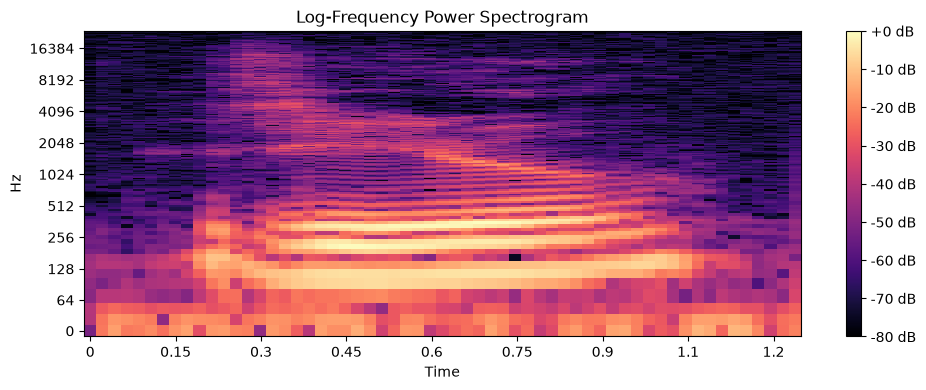

In [12]:
# visualize a .wav sample's spectrogram, selected randomly from just the first speaker in the dataset -- this was just nice to look at, and keep in mind

def get_random_file(folder_path):
    dir_path = Path(folder_path)

    # ignores subfolders
    files = [file for file in dir_path.iterdir() if file.is_file()]

    if not files:
        return None  # if folder is empty or only contains subdirectories

    # return a randomly selected file path
    random_file = random.choice(files)
    print(f"File selected: {random_file}")
    return random_file

def plot_spectrogram(file_path):
    # load audio file (librosa automatically handles resampling)
    y, sr = librosa.load(file_path, sr=None)

    # computing the Short-Time Fourier Transform (STFT)
    stft_matrix = librosa.stft(y)

    # converting amplitude to decibels (log scale)
    stft_db = librosa.amplitude_to_db(np.abs(stft_matrix), ref=np.max)

    # plot the spectrogram
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(stft_db, sr=sr, x_axis='time', y_axis='log', hop_length=1024, bins_per_octave=24, cmap='magma')

    plt.colorbar(format='%+2.0f dB')
    plt.title('Log-Frequency Power Spectrogram')
    plt.tight_layout()
    plt.show()

file_path = get_random_file(str(target_dir))
plot_spectrogram(file_path)

In [ ]:
# ADDED: attempt at Scaper
# because it writes files to disk, can't run per sample inside CachedDataset.__getitem__ every epoch
# here, generates noisy copies of training clips (mix each digit over background noise at a controlled SNR)
# might next just consolidate - remove the speed perturbation method and utilize Scaper for its pitch and time-stretch options

DURATION = 1.0  # seconds length; each soundscape is one digit over noise
LIMIT = 5   # trying 5 clips first, listen to them, then set to None

# Scaper requires soundbank of "foreground" and "background" folders, each w/ subfolders named after the label of the sounds inside
bank = Path("scaper_bank")
fg_root, bg_root = bank / "foreground", bank / "background"
out_dir, jams_dir = Path("scaper_out"), Path("scaper_jams")
for d in [fg_root, bg_root / "noise", out_dir, jams_dir]:
  d.mkdir(parents=True, exist_ok=True)
for digit in range(10):
  (fg_root / str(digit)).mkdir(exist_ok=True) # one foreground subfolder per digit!

# foreground soundbank - the TRAIN files only (never val/test, or near-copies would leak into training)
train_files = [full_ds.file_paths[i] for i in train_idx]  # turn train split's index numbers into file paths
for p in train_files:
  link = fg_root / p.name.split('_')[0] / p.name
  if not link.exists():
    link.symlink_to(p.resolve())  # make shortcut to original file instead of copying it (saves disk space)

# background soundbank - two synthetic noises (I could swap in real noise recordings for more realism, but just generating simple white and brown here)
rng = np.random.default_rng(0)  # using random number generator w/ a fixed seed for same noise every run
white = rng.standard_normal(10 * 48000) # 10s of random numbers at 48 kHz
brown = np.cumsum(white)  # nifty brown noise - adding random numbers up
brown -= np.convolve(brown, np.ones(4800) / 4800, mode="same")   # subtract a slow moving average (0.1 sec window) to remove the long, slow drift
for name, sig in [("white", white), ("brown", brown)]:
  # scaling each noise so its loudest point is 0.1 (quiet, no clipping) and save in the 'noise' background folder
  sf.write(str(bg_root / "noise" / f"{name}.wav"), 0.1 * sig / np.abs(sig).max(), 48000)

# generating one noisy copy per train clip here
n_ok, n_fail = 0, 0   # counters, so that we can report how many worked and how many failed
for p in (train_files[:LIMIT] if LIMIT else train_files):
  digit = p.name.split('_')[0]
  link = fg_root / digit / p.name   # clip's shortcut inside soundbank
  dur = min(sf.info(str(p)).duration - 0.01, DURATION)    # digit's file length (minus a hair) or 1 sec (whichever is shorter) so that Scaper never asks for more audio than exists
  try:
    sc = scaper.Scaper(DURATION, str(fg_root), str(bg_root))  # start a new and empty 1 second soundscape that knows where the soundbank is
    sc.ref_db = -50   # loudness of background noise; digit's loudness is set relative to this via snr below
    sc.add_background(label=('const', 'noise'), source_file=('choose', []),
                      source_time=('uniform', 0, 9))    # start reading the noise at a random point (0-9 sec into the 10-sec file) so a full 1 sec is always available
    sc.add_event(label=('const', digit), source_file=('const', str(link)),    # this event is digit being worked on
                 source_time=('const', 0), event_time=('const', 0),   # start reading clip from its start
                 event_duration=('const', dur),     # place it at start of soundscape
                 snr=('uniform', 5, 30),                   # dB vs background
                 pitch_shift=None, time_stretch=None)   # will turn these on after scrapping speed perturbation
    stem = p.stem + "_noisy"                               # eg '3_07_12_noisy.wav'
    sc.generate(str(out_dir / f"{stem}.wav"), str(jams_dir / f"{stem}.jams"),   # mix and save, plus a helpful .jams file that records exactly what was mixed in
                allow_repeated_label=True, allow_repeated_source=True,    # these two just let the same digit/file be reused w/o Scaper complaining
                disable_sox_warnings=True)    # hide annoying audio-tool warnings
    n_ok += 1
  except Exception as e:
    n_fail += 1
    if n_fail == 1: print("first failure:", repr(e))    # show only a first error message, so a repeated problem doesn't overwhelm my screen
print(f"generated {n_ok}, failed {n_fail}")

# Note though - the noise is frozen... each clip gets one fixed noisy copy, so it doesn’t re-roll every epoch the way CachedDataset does
# having both clean and noisy copies, plus the speed perturbation on top, kind of softens this?
# I could also maybe do something like loop twice with different file suffixes for two noisy copies
# Scaper feels clearly heavy to do for just noise mixing, but again, the idea is to expand its usage / get familiar

In [ ]:
# running locally in VS Code here, so setting device to MAC GPU
if torch.backends.mps.is_available():
  device = torch.device("mps")
  print("Mac GPU (MPS) is available")
else:
  device = torch.device("cpu")
  print("MPS not available. Falling back to CPU")

# cache each split as tensors -- so the audio is loaded/resampled once -- not every epoch!
# I needed the most help with this, wasn't familiar with the method itself
# MINOR CHANGE: that bad-clip skipping/check now occurs in here (more appropriate)
def cache_split(subset):
  xs, ys, bad = [], []
  for i in range(len(subset)):
    try:
      x, y = subset[i]
    except ValueError:  # now raise simple ValueError on empty WAVs (no str 'bad sample count' though)
      bad.append(i)
      continue
    x = x / x.abs().max().clamp(min=1e-8) # peak normalization
    xs.append(x)
    ys.append(y)
  return torch.stack(xs).unsqueeze(1), torch.tensor(ys) # [N, 1, 8000]

# implement cache_split()
# NOW all three splits are cached clean
Xtr, ytr = cache_split(train_dataset)  # this takes a moment
Xva, yva = cache_split(val_dataset)
Xte, yte = cache_split(test_dataset)
print("input shape:", Xtr.shape)  # [4000, 1, 8000]

# ADDED Scaper noisy copies (train only) to the clean train set
noisy_ds = AudioMNISTDataset(root_dir="scaper_out")
Xn, yn = cache_split(noisy_ds)
Xtr, ytr = torch.cat([Xtr, Xn]), torch.cat([ytr, yn])
print("train set with noisy copies:", Xtr.shape)
# CachedDataset below then speed perturbs all of it ad hoc, so the clean clips, the noisy copies and the random speed changes all combine
# val and test stay clean

# ADDED augmentation HERE instead -- from the cached clean tensors, so it can also re-roll every epoch
class CachedDataset(Dataset):
  def __init__(self, X, y, augment=False, sr=8000):
    self.X, self.Y, self.augment = X, y, augment
    # reminder to self: orig_freq = SAMPLE RATE of the audio, not its pitch
    self.speed = torchaudio.transforms.SpeedPerturbation(sr, [0.9, 1.1, 1.0, 1.0, 1.0])
    # also reminder to self: speed factor 0.9 w/ 20% prob, 1.1 w/ 20%, 1.0 (unchanged) w/ 60%
      # want to know whether this distribution of modulations is helpful within maybe an additional augmentation step

  def __len__(self):
    return len(self.y)

  def __getitem__(self, i):
    x = self.X[i]   # [1, 8000]
    if self.augment:
      x, _ = self.speed(x)    # reminder that 2nd output is 'lengths' (None here) and not a sr
      n = self.X.shape[-1]
      if x.shape[-1] < n:   # realized after speed perturbation, the clip is no longer *exactly 8000 samples long
        F.pad(x, (0, n - x.shape[-1]))    # add zeros (silence) to end of clip if too short
      else:
        x[..., :n]   # keep only the first n samples
    return x, self.y[i]

# LOADERS now wrap CachedDataset; ONLY the train loader augments!
train_loader = DataLoader(CachedDataset(Xtr, ytr, augment=True), batch_size=64, shuffle=True)
val_loader = DataLoader(CachedDataset(Xva, yva), batch_size=256)
test_loader = DataLoader(CachedDataset(Xte, yte), batch_size=256)

# 1D CNN (on the raw waveform)
class AudioCNN1D(nn.Module):
  def __init__(self, n_classes=10):
    super().__init__()
    self.features = nn.Sequential(
      # 32 learned filters; 80 samples = 10 ms at 8 kHz; stride 8; output length is 1001 for 8000 input (padding=36 would give exactly 1000)
        nn.Conv1d(1, 32, kernel_size=80, stride=8, padding=40),
        nn.BatchNorm1d(32),
        nn.ReLU(),
        nn.MaxPool1d(4),

        nn.Conv1d(32, 64, kernel_size=5, padding=2),
        nn.BatchNorm1d(64),
        nn.ReLU(),
        nn.MaxPool1d(4),

        nn.Conv1d(64, 128, kernel_size=5, padding=2),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.AdaptiveAvgPool1d(1),
    )
    self.classifier = nn.Linear(128, n_classes)

  def forward(self, x):
    x = self.features(x)
    return self.classifier(x.flatten(1))

model = AudioCNN1D().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# a single function including train / val / test passes
def run_epoch(loader, train=False):
  model.train(train) # train mode
  total_loss, correct, n = 0.0, 0, 0
  with torch.set_grad_enabled(train):
    for x, y in loader:
      x, y = x.to(device), y.to(device)
      logits = model(x)
      loss = loss_fn(logits, y)

      if train:
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

      total_loss += loss.item() * len(y)
      correct += (logits.argmax(dim=1) == y).sum().item()
      n += len(y)

  return total_loss / n, correct / n

# compile history for plotting
hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

# train, validate each epoch and keeping the best weights
best_val_acc, best_state = 0.0, None
for epoch in range(20):
  tr_loss, tr_acc = run_epoch(train_loader, train=True)
  va_loss, va_acc = run_epoch(val_loader)

  hist["train_loss"].append(tr_loss)
  hist["train_acc"].append(tr_acc)
  hist["val_loss"].append(va_loss)
  hist["val_acc"].append(va_acc)

  print(f"epoch {epoch+1:2d} | train loss {tr_loss:.4f} acc {tr_acc:.1%} | val loss {va_loss:.4f} acc {va_acc:.1%}")

  if va_acc > best_val_acc:
    best_val_acc = va_acc
    best_state = copy.deepcopy(model.state_dict())

# test once, using the best-on-validation weights
model.load_state_dict(best_state)
te_loss, te_acc = run_epoch(test_loader)
print(f"\nTEST | loss {te_loss:.4f} | acc {te_acc:.1%}")

# replace initial plt. function below with TB now.
# use 'tr_loss', 'tr_acc', 'va_loss', 'va_acc' as variables for plotting -> eventually switch to eval/val/train.
# have to create separate 'for loop'?

writer = SummaryWriter("AudioMNIST-CNN-Results")  # writer will output to ./runs/ directory by default
r = 5 # ADJUST - value just from tutorial.
for i in range(1, len(hist["train_loss"]) + 1):
  writer.add_scalars("loss", {"train": hist["train_loss"][i - 1], "val": hist["val_loss"][i - 1]}, i)
writer.close()
# this call adds three values to the same scalar plot with the tag
# 'loss' in TensorBoard's scalar section

# add accuracy

###
# graphing of train vs. validation over training
# ep = range(1, len(hist["train_loss"]) + 1)
# fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# axes[0].plot(ep, hist["train_loss"], label="train")
# axes[0].plot(ep, hist["val_loss"], label="validation")
# axes[0].set_title("loss per epoch")
# axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss")

# axes[1].plot(ep, [a * 100 for a in hist["train_acc"]], label="train")
# axes[1].plot(ep, [a * 100 for a in hist["val_acc"]], label="validation")
# axes[1].set_title("accuracy per epoch")
# axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy (%)")

# for ax in axes:
#   ax.grid(alpha=0.3)
#   ax.legend()
# plt.tight_layout()
# plt.show()

# # per-epoch table
# print(pd.DataFrame(hist, index=pd.Index(ep, name="epoch")).round(4))

Mac GPU (MPS) is available
bad sample count: 0
input shape: torch.Size([4000, 1, 48000])
epoch  1 | train loss 1.6471 acc 61.1% | val loss 1.3721 acc 73.4%
epoch  2 | train loss 0.9292 acc 88.7% | val loss 0.6333 acc 95.8%
epoch  3 | train loss 0.5606 acc 95.0% | val loss 0.6294 acc 77.6%
epoch  4 | train loss 0.3555 acc 96.8% | val loss 0.3434 acc 95.6%
epoch  5 | train loss 0.2527 acc 97.7% | val loss 0.2373 acc 96.8%
epoch  6 | train loss 0.1832 acc 98.4% | val loss 0.2977 acc 90.2%
epoch  7 | train loss 0.1459 acc 98.7% | val loss 0.1552 acc 97.8%
epoch  8 | train loss 0.1109 acc 99.2% | val loss 0.1020 acc 98.6%
epoch  9 | train loss 0.0978 acc 99.1% | val loss 0.1065 acc 97.6%
epoch 10 | train loss 0.0799 acc 99.3% | val loss 0.0697 acc 99.0%
epoch 11 | train loss 0.0681 acc 99.4% | val loss 0.3636 acc 85.2%
epoch 12 | train loss 0.0591 acc 99.4% | val loss 0.0719 acc 99.6%
epoch 13 | train loss 0.0539 acc 99.5% | val loss 0.0851 acc 98.6%
epoch 14 | train loss 0.0482 acc 99.5% |

File selected: /Users/madelinemccormack/Desktop/PhD/PersonalResearch/AudioMNIST_CNN/audio-mm/3-M-01.wav
my selected (processed) clip:


prediction: 7 (71.9% confident)
Top 3:  7 (71.9%),  9 (27.2%),  1 (0.7%)
true digit: 3 -> wrong
1-M-01.wav           true=1 pred=1 ok
2-M-01.wav           true=2 pred=7 X
3-M-01.wav           true=3 pred=7 X
4-M-01.wav           true=4 pred=4 ok
5-M-01.wav           true=5 pred=9 X
6-M-01.wav           true=6 pred=6 ok
7-M-01.wav           true=7 pred=7 ok
8-M-01.wav           true=8 pred=7 X
9-M-01.wav           true=9 pred=9 ok

Accuracy on my recordings: 0.5555555555555556


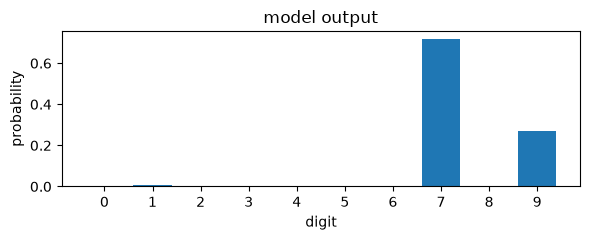

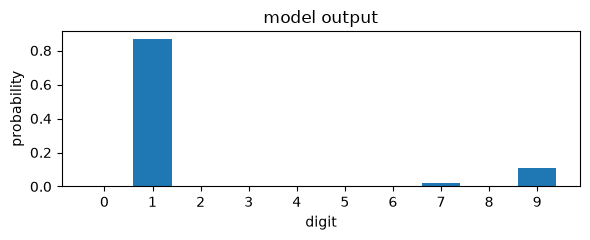

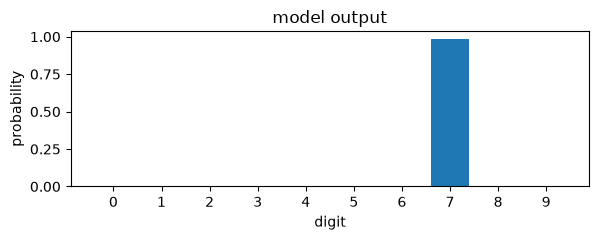

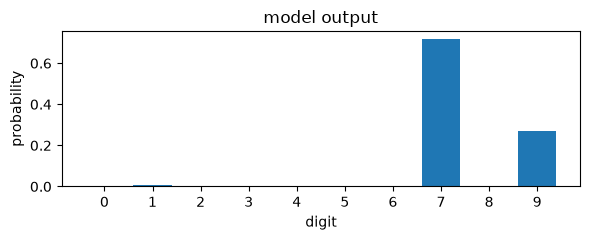

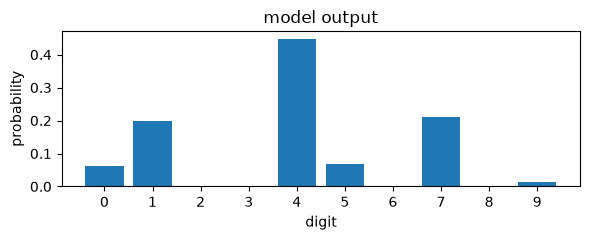

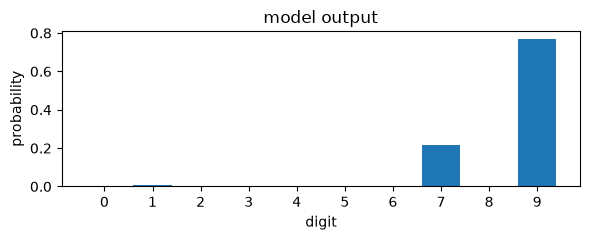

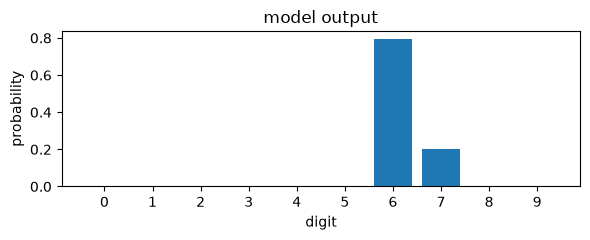

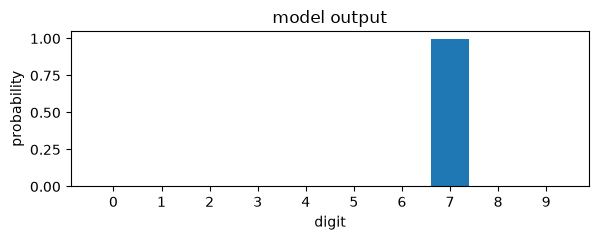

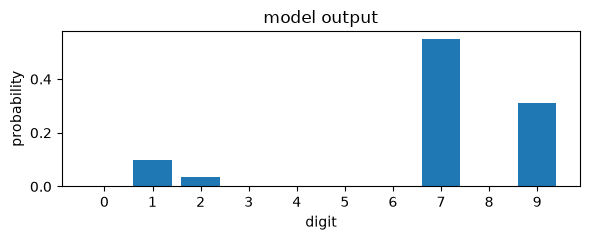

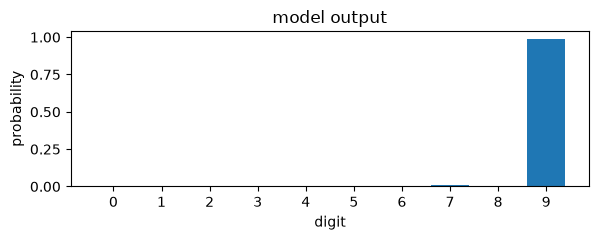

In [ ]:
# load, play, and test own audio samples against CNN
# 10.25 added TensorBoard; just using model charting (e.g. over epochs) for now

# from google.colab import drive
# drive.mount('/content/drive')

audio_mm_folder = Path.cwd() / "audio-mm"

AUDIO_EXTS = {".wav", ".m4a"}

def get_random_file(folder_path):
    # only picks audio files within the folder
    files = [f for f in Path(folder_path).iterdir() if f.is_file() and f.suffix.lower() in AUDIO_EXTS]
    if not files:
        return None  # if folder is empty or only contains subdirectories

    # return a randomly selected file path
    random_file = random.choice(files)
    print(f"File selected: {random_file}")
    return random_file

# do same preprocessing that the training data got (mono, 8 kHz, 8000 samples, peak-norm'd)
def prepare_clip(path, target_sr=8000, num_samples=8000, silence_thresh=0.1):
  waveform, sr = torchaudio.load(str(path))
  waveform = waveform.mean(dim=0, keepdim=True)
  if sr != target_sr:
    waveform = torchaudio.functional.resample(waveform, sr, target_sr)

  n = waveform.shape[1] # pad/trim to 1 sec
  if n < num_samples:
    waveform = F.pad(waveform, (0, num_samples - n))
  else:
    waveform = waveform[:, :num_samples]

  return waveform / waveform.abs().max().clamp(min=1e-8)  # again, same peak normalization

# just run one file through the model
def classify_file(path, show=True):
  wav = prepare_clip(path)
  model.eval() # returning logits / raw scores. one per digit (shape[1, 10])
  with torch.no_grad():
    probs = torch.softmax(model(wav.unsqueeze(0).to(device)), dim=1)[0].cpu() # input [1, 1, 8000]; removes the batch-of-one dimension
  pred = int(probs.argmax())

  # get the true label from the filename with assumption the first number is the digit
  try:
    true = int(Path(path).name.split("-")[0])
  except ValueError:
    true = None

  # create explicit figure and axes objects -- can use either with plt.show() in notebook or for TB
  fig, ax = plt.subplots(figsize=(6, 2.5))
  ax.bar(range(10), probs.numpy())
  ax.set_xticks(range(10))
  ax.set_xlabel("digit")
  ax.set_ylabel("probability")
  ax.set_title("model output")
  fig.tight_layout()

  if show:
    print("my selected (processed) clip:")
    display(Audio(wav.squeeze(0).numpy(), rate=8000))
    top_p, top_d = probs.topk(3)  # returns the 3 largest values (in probs) -> top_p probs' values, top_d digits
    print(f"prediction: {pred} ({probs[pred]:.1%} confident)")
    print("Top 3:", ", ".join(f" {int(d)} ({p:.1%})" for p, d in zip(top_p, top_d)))
    if true is not None:
      print(f"true digit: {true} -> {'correct' if pred == true else 'wrong'}")

  return pred, true, fig

# one random recording - but can switch to cycling through all 10 of them
random_audio_file = get_random_file(str(audio_mm_folder))
pred, true, fig = classify_file(random_audio_file)

# use all of my recordings at once + an overall score
results = []
for f in sorted(Path(str(audio_mm_folder)).iterdir()):
  if f.suffix.lower() in AUDIO_EXTS:
    pred, true, run_fig = classify_file(f, show=False)
    results.append((f.name, true, pred))
    print(f"{f.name:20s} true={true} pred={pred} {'ok' if pred == true else 'X'}")
scored = [(t, p) for _, t, p in results if t is not None]
if scored:
  model_total_acc = sum(t == p for t, p in scored) / len(scored)
  print(f"\nAccuracy on my recordings: {model_total_acc}")

# calculate accuracy per unique digit label (0-9) -> specifically for TB usage, rather than a crude matplot graph I was doing before
accuracy_per_digit = {}
for digit in range(10):
  digit_samples = [pair for pair in scored if pair[0] == digit]
  if len(digit_samples) > 0:
    acc = sum(t == p for t, p in digit_samples) / len(digit_samples)
    accuracy_per_digit[digit] = acc
  else:
    accuracy_per_digit[digit] = 0.0 # no samples for this digit in custom dataset

writer = SummaryWriter("AudioMNIST-CNN-Input-Results")
for digit, acc in accuracy_per_digit.items():
  writer.add_scalar("Accuracy_Per_Digit", acc, global_step=digit) # kind of would have preferred this to show probability up to 1f (to be as clear as possible + show how bad the model's accuracy was against my inputs)

writer.close()

In [17]:
# load the TensorBoard notebook extension
%load_ext tensorboard

# open TensorBoard pointing to my model's main log directory
%tensorboard --logdir AudioMNIST-CNN-Results

# open TensorBoard pointing to my model's main log directory
%tensorboard --logdir AudioMNIST-CNN-Input-Results

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 7100), started 0:01:41 ago. (Use '!kill 7100' to kill it.)

Reusing TensorBoard on port 6007 (pid 7101), started 0:01:41 ago. (Use '!kill 7101' to kill it.)